<a href="https://colab.research.google.com/github/nguefackuriel/autoscope-opencv/blob/b%2Fparasite-detectors/notebooks/detectors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AutoScope: parasite box detectors

Trains **YOLO26** and **Faster R-CNN** to find malaria parasites, on the same
patient split every published number in this repo uses.

Runs on an **Azure ML compute instance**, a local GPU box, or **Colab**.

On Azure ML or locally it finds the repo from wherever this notebook sits, so
you just pull the branch and open it. On Colab, where the VM starts empty, the
first cell clones the repo (asking for a GitHub token, since it is private),
keeps Colab's own torch rather than replacing it, and caches the exported tiles
on Drive so a second session starts at training.

**Training needs a GPU.** The export, the visualisation and the annotation
measurements all run fine on CPU; training does not. Measured: a YOLO26s train
step is about 2 s per image on 8 CPU cores, which is 7.8 hours per epoch on
13 510 tiles. A T4 does the same epoch in two to four minutes.

## The rules this notebook enforces

1. **The split is inherited, not chosen.** `eval/results/wbc_sweep.json` ->
   `fit_patients` is 100 patient ids; the held-out 50 are the complement.
2. **Validation comes out of the fit patients**, 80/20 by patient.
3. **The held-out 50 are scored once**, at the bottom, at a threshold already
   decided. `detector_eval.py` refuses to sweep thresholds on them.

The number to beat, on those held-out patients: the patch network at its
shipped 0.75 threshold -- **precision 0.790, recall 0.739, F1 0.763, count
bias -6.4%**.

Quote the count bias next to the F1. The threshold moved from 0.80 to 0.75 not
because F1 improved (0.762 vs 0.763) but because 0.80 ran the count 14.4% low,
and the count is the denominator of every density a clinician reads.

In [24]:
%%bash
cd /content/autoscope-opencv
git fetch origin && git reset --hard origin/b/parasite-detectors && git log --oneline -1

HEAD is now at 2d034c8 Evaluation no longer requires retraining in the same session
2d034c8 Evaluation no longer requires retraining in the same session


From https://github.com/nguefackuriel/autoscope-opencv
   38c1121..2d034c8  b/parasite-detectors -> origin/b/parasite-detectors


## 1. Find the repo and the hardware

In [1]:
import os, platform, shutil, subprocess, sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
BRANCH = 'b/parasite-detectors'
OWNER_REPO = 'nguefackuriel/autoscope-opencv'

def find_repo(start=None):
    here = Path(start or os.getcwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'pyproject.toml').exists() and (d / 'src' / 'autoscope').exists():
            return d
    return None

# Azure ML and a local box already hold the checkout. Colab starts empty, so
# the repo has to be cloned before anything can find it. The repo is private
# and its remote is SSH, which Colab cannot use, so this clones over HTTPS with
# a token read by getpass -- never written into the notebook or its output.
if find_repo() is None and IN_COLAB:
    import getpass
    target = Path('/content/autoscope-opencv')
    if not target.exists():
        token = getpass.getpass('GitHub token (input hidden): ')
        r = subprocess.run(['git', 'clone', '--branch', BRANCH, '--single-branch',
                            f'https://{token}@github.com/{OWNER_REPO}.git', str(target)],
                           capture_output=True, text=True)
        del token
        if r.returncode:
            raise SystemExit('clone failed: ' + r.stderr[-400:].replace(
                'https://', 'https://***@').split('@')[-1])
    os.chdir(target)

ROOT = find_repo()
if ROOT is None:
    raise SystemExit(
        'Cannot find the repo root. On Azure ML or locally, run this notebook '
        'from inside the checkout. On Colab the clone above should have made '
        'one at /content/autoscope-opencv.')
os.chdir(ROOT)
print('repo   :', ROOT)
print('python :', platform.python_version(), '|', platform.platform())

# Fail here, clearly, rather than 40 lines into pip.
# numpy 2.3.4 and scipy 1.16.3 both require Python >= 3.11. On 3.10 pip cannot
# see them and reports "No matching distribution found for numpy==2.3.4", which
# reads like a numpy problem and is a Python problem.
if sys.version_info < (3, 11):
    raise SystemExit(
        f"This kernel is Python {platform.python_version()}; the project needs 3.11+\n"
        f"(pyproject.toml declares requires-python = '>=3.11').\n\n"
        "numpy 2.3.4 and scipy 1.16.3 both require >= 3.11, so the pinned\n"
        "requirements cannot install here.\n\n"
        "On an Azure ML compute instance, make a 3.11 kernel and select it:\n"
        "  conda create -n autoscope python=3.11 -y\n"
        "  conda activate autoscope\n"
        "  pip install -r requirements.txt -r requirements-detect.txt ipykernel\n"
        "  python -m ipykernel install --user --name autoscope "
        "--display-name 'AutoScope 3.11'\n"
        "then Kernel > Change kernel > AutoScope 3.11.")

try:
    print(subprocess.run(['nvidia-smi','--query-gpu=name,memory.total','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip() or 'nvidia-smi: no GPU listed')
except FileNotFoundError:
    print('nvidia-smi not found -- no NVIDIA driver on this machine')

repo   : /content/autoscope-opencv
python : 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
Tesla T4, 15360 MiB


### Pull the latest code

Safe to run at any time. Nothing of value is tracked by git -- the exported
tiles, the trained models and the dataset are all gitignored or on Drive -- so
discarding local changes costs nothing and avoids a merge conflict over a file
you did not mean to edit.

**Restart the kernel afterwards** if this reports new commits: Python has
already imported the old modules, and autoreload cannot always replace a module
that changed underneath a running interpreter.

In [2]:
UPDATE = True

# GIT_TERMINAL_PROMPT=0 so a credential prompt fails instead of hanging: a
# blocked fetch waits forever on a prompt nobody can see, and never reaches the
# re-authentication below. The timeout is the same idea for a stalled network.
GITENV = dict(os.environ, GIT_TERMINAL_PROMPT='0', GIT_ASKPASS='echo',
              SSH_ASKPASS='echo')

if UPDATE:
    before = subprocess.run(['git','rev-parse','--short','HEAD'], cwd=str(ROOT),
                            capture_output=True, text=True).stdout.strip()
    f = subprocess.run(['git','fetch','origin'], cwd=str(ROOT), env=GITENV,
                       capture_output=True, text=True, timeout=180)
    if f.returncode:
        # The clone embedded a token in the remote URL. If it has expired or the
        # repo was cloned another way, ask for one rather than failing opaquely.
        print('fetch failed; re-authenticating')
        import getpass
        tok = getpass.getpass('GitHub token (input hidden): ')
        subprocess.run(['git','remote','set-url','origin',
                        f'https://{tok}@github.com/{OWNER_REPO}.git'],
                       cwd=str(ROOT), check=True)
        del tok
        f = subprocess.run(['git','fetch','origin'], cwd=str(ROOT), env=GITENV,
                           capture_output=True, text=True, timeout=180)
        if f.returncode:
            raise SystemExit('fetch still failing: ' + f.stderr[-300:])

    subprocess.run(['git','reset','--hard',f'origin/{BRANCH}'], cwd=str(ROOT),
                   capture_output=True, text=True, check=True, timeout=180)
    after = subprocess.run(['git','rev-parse','--short','HEAD'], cwd=str(ROOT),
                           capture_output=True, text=True).stdout.strip()

    if before == after:
        print(f'already up to date at {after}')
    else:
        log = subprocess.run(['git','log','--oneline',f'{before}..{after}'],
                             cwd=str(ROOT), capture_output=True, text=True).stdout
        print(f'{before} -> {after}')
        print(log.strip() or '(no commit list)')
        print('')
        print('RESTART THE KERNEL now: Runtime > Restart session, then run '
              'from the top.')

already up to date at 38c1121


## 2. Dependencies

**Needs Python 3.11 or newer.** `numpy==2.3.4` and `scipy==1.16.3` both
require it, and on 3.10 pip reports that as *"No matching distribution found
for numpy==2.3.4"*, which reads like a numpy problem and is a Python one. The
cell above fails fast with the fix if the kernel is too old.

`requirements.txt` + `requirements-detect.txt` resolve together on Linux with
**numpy 2.3.4** throughout. They did not always: `requirements-train.txt` used
to pin `numpy<2` for an Intel-Mac torch wheel, which could not coexist with
opencv-python 5 (`numpy>=2`). That is fixed, so all three install side by side.

If the Azure ML image already ships a different numpy, this pins it back. Restart
the kernel afterwards if pip says it upgraded numpy.

In [3]:
INSTALL = True   # set False once the environment is built

if IN_COLAB:
    # Keep Colab's torch. It is built against the CUDA on Colab's VMs, and
    # replacing it with the PyPI pin risks a build that cannot see the GPU --
    # which is the whole reason for being on Colab. Everything else is pinned.
    pkgs = ['-r', 'requirements.txt', 'ultralytics==8.4.142', 'clearml==2.1.12',
            'matplotlib']
    print('Colab: keeping the preinstalled torch, pinning everything else.')
else:
    pkgs = ['-r', 'requirements.txt', '-r', 'requirements-detect.txt', 'matplotlib']

if INSTALL:
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs,
                       capture_output=True, text=True)
    print(r.stdout[-3000:] or 'installed')
    if r.returncode:
        print('STDERR:', r.stderr[-3000:])

Colab: keeping the preinstalled torch, pinning everything else.
installed


In [4]:
# The scripts carry a sys.path preamble, so no `pip install -e .` is needed --
# which is exactly what Azure ML does not do for a code snapshot.
sys.path[:0] = [str(ROOT / d) for d in ('src','eval','train')]

# This notebook sits next to code that is still being edited, and Python caches
# imported modules. Without autoreload you get an AttributeError for a function
# that plainly exists on disk, because the kernel is holding the older copy.
try:
    _ip = get_ipython()
    _ip.run_line_magic('load_ext', 'autoreload')
    _ip.run_line_magic('autoreload', '2')
    print('autoreload on: edits to src/ and eval/ take effect without a restart')
except Exception:
    pass

import importlib
import json
import numpy, cv2, torch
from autoscope import annotations as ann, boxes as bx, parasites as par
import splits

# Belt and braces: autoreload cannot help a module the kernel imported before
# autoreload was switched on, which is exactly the long-running-kernel case.
for _m in (ann, bx, par, splits):
    importlib.reload(_m)
import splits          # rebind, so the name points at the reloaded module

missing = [n for n in ('inference_sample','annotated_images','unannotated_images',
                       'assert_measurable','train_val','holdout_patients')
           if not hasattr(splits, n)]
assert not missing, (f'splits is stale, missing {missing}. '
                     'Restart the kernel: Kernel > Restart and Run All.')

ENV = {'python': platform.python_version(), 'numpy': numpy.__version__,
       'opencv': cv2.__version__, 'torch': torch.__version__,
       'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0)
       if torch.cuda.is_available() else None}
print(json.dumps(ENV, indent=2))
(ROOT/'eval'/'results').mkdir(parents=True, exist_ok=True)
(ROOT/'eval'/'results'/'run_env.json').write_text(json.dumps(ENV, indent=2))
if not torch.cuda.is_available():
    print('\nWARNING: no CUDA. Export and visualisation are fine; training is not.')

{
  "python": "3.13.15",
  "numpy": "2.3.4",
  "opencv": "5.0.0",
  "torch": "2.11.0+cu128",
  "cuda": "12.8",
  "gpu": "Tesla T4"
}


### A runner that shows progress

`subprocess.run` writes to the kernel's file descriptor, which Colab does not
reliably route into the cell: a two-hour training run appears to produce
nothing until it ends. Python also buffers its own stdout when it is not
attached to a terminal, so even captured output arrives in 8 KB chunks.

`run()` below fixes both: `-u` for unbuffered child output, and a pipe read a
character at a time that breaks on carriage returns as well as newlines.

That last part matters more than it sounds. `for line in pipe` waits for a
newline, and tqdm redraws with a carriage return only -- so ultralytics
scanning 13 510 labels behind a progress bar produced total silence until it
finished. The output was never lost; it was sitting in the buffer with no
newline to release it.

In [5]:
def run(cmd, cwd=None):
    """Run a script, streaming its output into this cell as it happens.

    Splits on carriage returns as well as newlines, so a tqdm progress bar
    shows up as it redraws instead of appearing only once it finishes.
    """
    cmd = [str(c) for c in cmd]
    print(' '.join(cmd))
    print('')
    proc = subprocess.Popen(cmd, cwd=str(cwd or ROOT),
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    CR, NL = chr(13), chr(10)      # written this way so the generator cannot
                                   # turn an escape into a real newline

    # Read a character at a time and break on EITHER separator.
    # `for line in proc.stdout` waits for a newline, and tqdm redraws with a
    # carriage return only -- so ultralytics scanning 13 510 labels behind a
    # progress bar produced total silence until it finished. The output was not
    # lost, it was sitting in the buffer with no newline to release it.
    buf = []
    while True:
        ch = proc.stdout.read(1)
        if not ch:
            break
        if ch in (CR, NL):
            text = ''.join(buf).rstrip()
            buf = []
            if text:
                print(text, flush=True)
        else:
            buf.append(ch)
    if buf:
        print(''.join(buf).rstrip(), flush=True)
    code = proc.wait()
    print('')
    print(f'[exit {code}]')
    return code

## 3. The dataset

`data/download.py` refuses to start without ~12 GB free, because a half
download onto a full disk fails in a far more confusing way than a refusal.

In [6]:
import shutil

RAW = ROOT/'data'/'raw'
free = shutil.disk_usage(ROOT).free
print(f'free disk: {free/1e9:.1f} GB')

have = RAW.exists() and any(p.name.startswith('TF') for p in RAW.glob('*'))
if not have:
    print('downloading the NLM set (3.9 GB)...')
    r = subprocess.run([sys.executable,'data/download.py'], cwd=str(ROOT))
    if r.returncode: raise SystemExit('download failed -- see the output above')
else:
    print('dataset already present')

root = splits.patient_root()
print('patient root:', root)
print('patients    :', len(splits.all_patients()))

free disk: 38.8 GB
dataset already present
patient root: /content/autoscope-opencv/data/raw
patients    : 150


### Verify the split before anything reads an image

In [7]:
allp = splits.all_patients()
fit  = splits.fit_patients()
hold = splits.holdout_patients()
train_ids, val_ids = splits.train_val()

print(f'patients {len(allp)} | fit {len(fit & set(allp))} | holdout {len(hold)}')
print(f'train {len(train_ids)} | val {len(val_ids)}')
assert len(allp) == 150, f'expected 150 patients, found {len(allp)}'
assert len(hold) == 50,  f'expected 50 held out, found {len(hold)}'
assert not (set(train_ids) | set(val_ids)) & set(hold), 'held-out patient leaked into training'
print('\nsplit checks passed')

patients 150 | fit 100 | holdout 50
train 80 | val 20

split checks passed


### The reserved inference sample

53 of the 1883 images carry no ground truth file. That is by design: the
dataset ReadMe says annotation stops once 200 white cells have been counted,
because that is enough to compute a parasitaemia.

A detection on one of those images cannot be scored right or wrong, so they are
excluded from training, validation and test. They are **reserved**: once a model
is chosen and evaluation is finished, they are the images it is finally run over
for a qualitative look, on fields nothing was fitted to.

Every sampling site in `eval/` goes through `splits.annotated_images()`, and a
test fails if any script globs images directly.

In [8]:
reserved = splits.inference_sample()
print(f'reserved for inference : {len(reserved)} images')
print(f'across                 : {len({p.parent.name for p in reserved})} patients')

fitset = set(train_ids) | set(val_ids)
print(f'  from fit patients    : {sum(1 for p in reserved if p.parent.name in fitset)}')
print(f'  from holdout patients: {sum(1 for p in reserved if p.parent.name in set(hold))}')

usable = sum(len(splits.annotated_images(p)) for p in allp)
print(f'\nusable for measurement : {usable} images')
for p in reserved[:5]:
    print('   ', p.parent.name + '/' + p.name)
print('    ...')

reserved for inference : 53 images
across                 : 37 patients
  from fit patients    : 26
  from holdout patients: 27

usable for measurement : 1830 images
    TF108_256/20170830_153525.jpg
    TF108_256/20170830_160538.jpg
    TF10_C65P26/20170612_145535.jpg
    TF112_CJ10/20170830_203623.jpg
    TF114_SC518/20170830_220137.jpg
    ...


### What the annotations are

Two shapes, and only two. The ReadMe says either label may be stored as a
`Circle` or a `Point`, which would mean the parser silently drops combinations
it does not handle -- so this checks rather than assumes.

In [9]:
from collections import Counter

combo = Counter()
for p in allp:
    for g in sorted((ann.gt_path(i) for i in splits.annotated_images(p))):
        for line in g.read_text(errors='ignore').splitlines()[1:]:
            q = line.split(',')
            if len(q) >= 7:
                combo[(q[1].strip(), q[3].strip())] += 1

total = sum(combo.values())
print(f'{total} annotation lines\n')
print(f"{'label':<20}{'shape':<10}{'count':>10}")
for (lab, shape), c in combo.most_common():
    print(f'{lab:<20}{shape:<10}{c:>10}')
print('\nThe ReadMe states 84509 parasites and 35449 white cells.')

119958 annotation lines

label               shape          count
Parasite            Circle         84509
White_Blood_Cell    Point          35449

The ReadMe states 84509 parasites and 35449 white cells.


## 4. Look at the data before modelling it

Three things worth seeing with your own eyes, because each one has already
caused a bug in this project:

- the **annotations land on the cells** (the EXIF orientation trap),
- a parasite is genuinely **tiny** next to a white cell,
- the annotator's **circle is far bigger than the parasite**, which is why
  boxes are derived from the stain rather than drawn from the circle.

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv

def pick_image(patient=None, min_parasites=20):
    """An annotated field with plenty of parasites, from a FIT patient."""
    pool = [patient] if patient else sorted(train_ids)
    for p in pool:
        for ip in sorted((root/p).glob('*.jpg')):
            if not ann.gt_path(ip).exists():
                continue
            img = cv.imread(str(ip))
            if img is None: continue
            h, w = img.shape[:2]
            t = ann.for_image(ip, w, h)
            if t and len(t.parasites) >= min_parasites:
                return ip, img, t
    raise SystemExit('no suitable image found')

IMG_PATH, IMG, TRUTH = pick_image()
print(IMG_PATH)
print(f'{IMG.shape[1]} x {IMG.shape[0]} px | '
      f'{len(TRUTH.parasites)} parasites | {len(TRUTH.white_cells)} white cells')

/content/autoscope-opencv/data/raw/TF105_245/20170830_140427.jpg
3024 x 4032 px | 214 parasites | 28 white cells


### The whole field, annotations overlaid

Parasites in red (the circle is the **annotator's**, not the object), white
cells in cyan. If the markers sat off the cells, the EXIF orientation flag
would be being read wrongly -- that is the failure this view catches instantly.

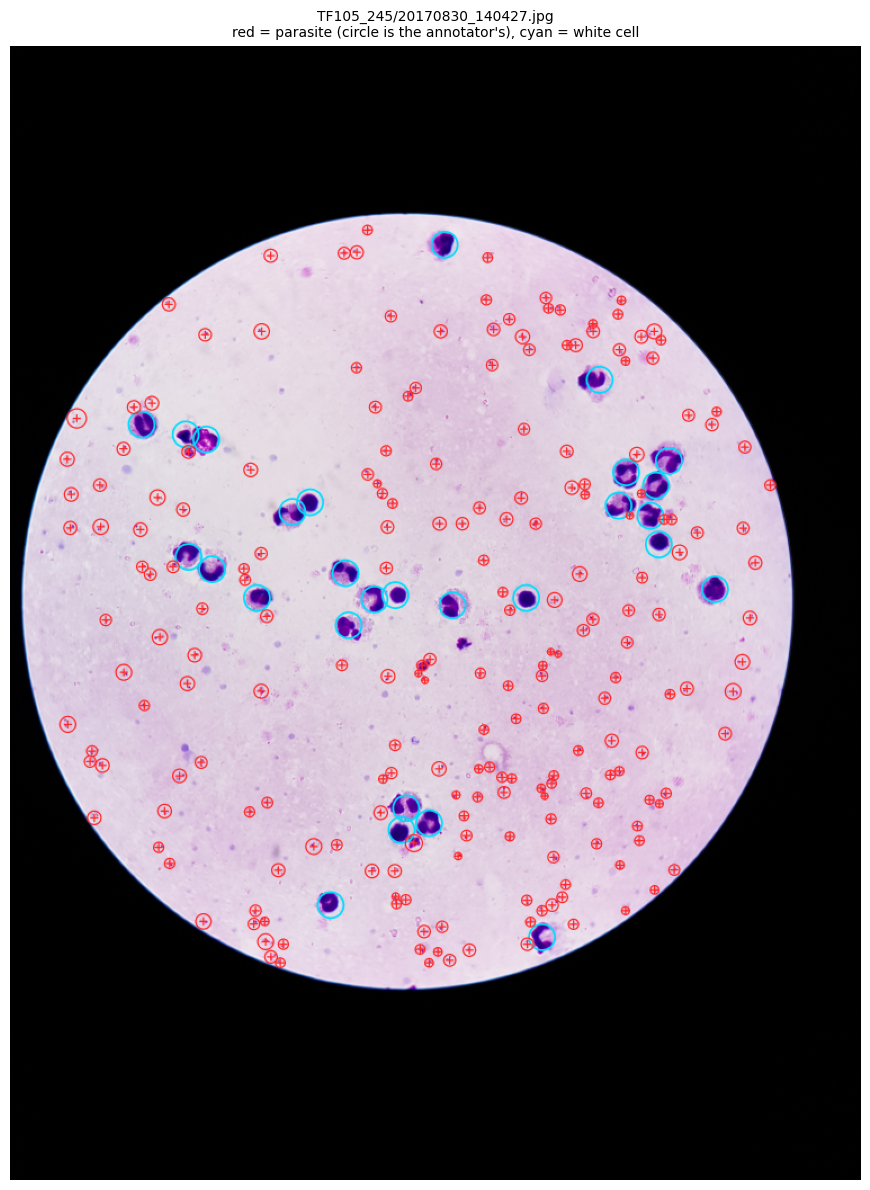

In [11]:
def overlay(img, truth, scale=0.25, circles=True):
    vis = cv.cvtColor(img, cv.COLOR_BGR2RGB).copy()
    for a in truth.white_cells:
        cv.circle(vis, (int(a.x), int(a.y)), 46, (0, 220, 255), 6)
    for a in truth.parasites:
        if circles and a.radius:
            cv.circle(vis, (int(a.x), int(a.y)), int(a.radius), (255, 40, 40), 4)
        cv.drawMarker(vis, (int(a.x), int(a.y)), (255, 40, 40),
                      cv.MARKER_CROSS, 26, 4)
    return cv.resize(vis, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)

plt.figure(figsize=(9, 12))
plt.imshow(overlay(IMG, TRUTH))
plt.title(f'{IMG_PATH.parent.name}/{IMG_PATH.name}\n'
          f'red = parasite (circle is the annotator\'s), cyan = white cell', fontsize=10)
plt.axis('off'); plt.tight_layout(); plt.show()

### Native resolution, where the real problem shows

The same field, uncropped and unscaled. A parasite is about **10 px**; a white
cell nucleus is about **100**. This is why the export tiles at native
resolution: resize a 3000 px field to 640 and the parasite becomes 2 px, below
what any box head can regress.

The red circle is the annotator's. The green box is what `boxes.py` derives
from the stain. Measured across 953 parasites, the circle is about **3.3x**
the parasite across, so drawing boxes from it would make every target roughly
eleven times too large in area.

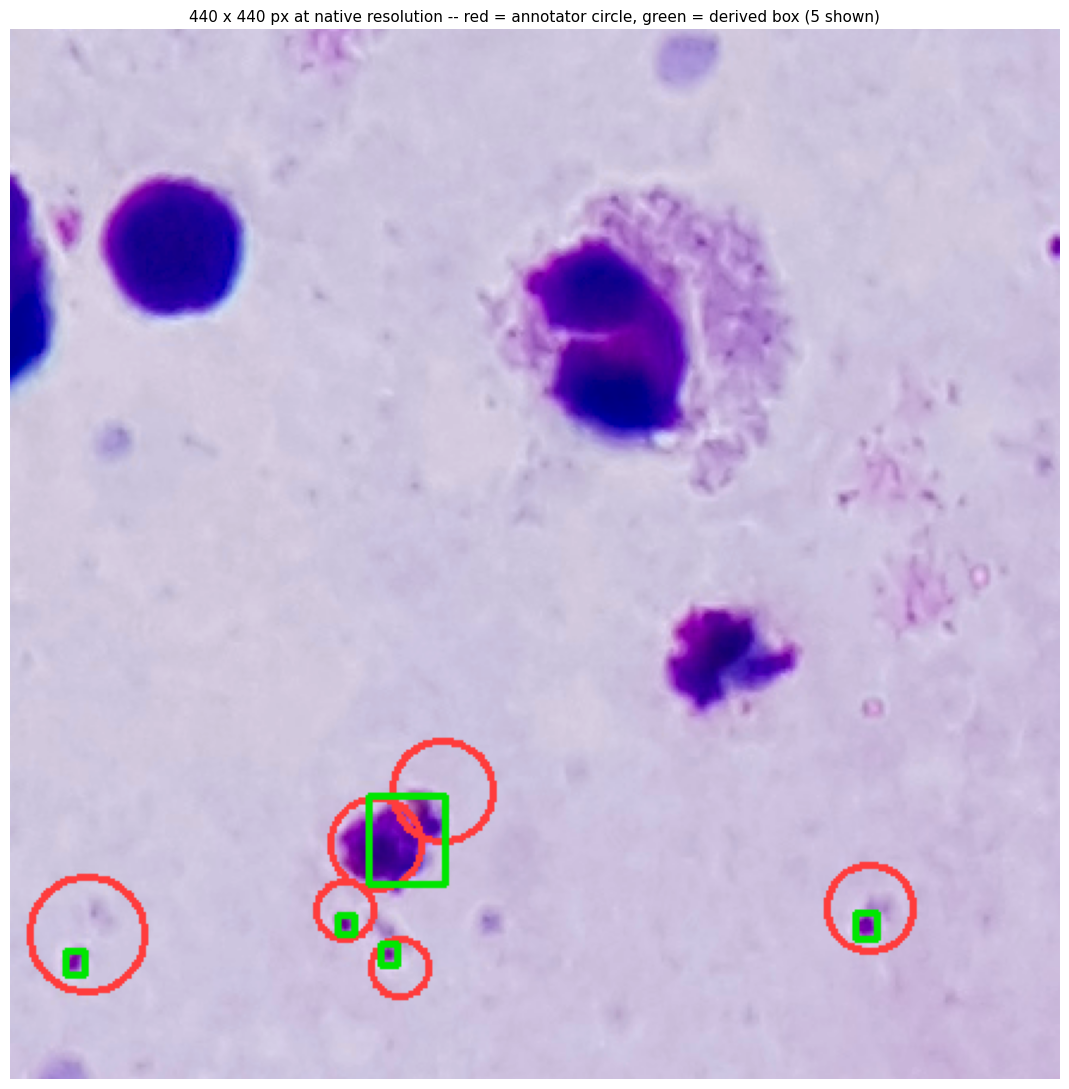

In [12]:
prep, mask, ox, oy = par._prepare(IMG, True, True)
top, _, _ = par.tophat(prep)

# centre the crop on the densest clump of parasites
pts = np.array([[p.x - ox, p.y - oy] for p in TRUTH.parasites])
inside = pts[(pts[:,0] > 200) & (pts[:,1] > 200) &
             (pts[:,0] < prep.shape[1]-200) & (pts[:,1] < prep.shape[0]-200)]
cx, cy = (inside.mean(axis=0) if len(inside) else
          np.array([prep.shape[1]/2, prep.shape[0]/2])).astype(int)
R = 220
x0, y0 = max(cx-R, 0), max(cy-R, 0)
crop = prep[y0:y0+2*R, x0:x0+2*R].copy()
vis = cv.cvtColor(crop, cv.COLOR_BGR2RGB)

n_box = 0
for p in TRUTH.parasites:
    px, py = p.x - ox - x0, p.y - oy - y0
    if not (0 <= px < 2*R and 0 <= py < 2*R):
        continue
    if p.radius:
        cv.circle(vis, (int(px), int(py)), int(p.radius), (255, 60, 60), 2)
    b = bx.box_at(top, p.x - ox, p.y - oy, p.radius)
    if b is not None:
        cv.rectangle(vis, (int(b.x - x0), int(b.y - y0)),
                     (int(b.x + b.w - x0), int(b.y + b.h - y0)), (0, 230, 0), 2)
        n_box += 1

plt.figure(figsize=(11, 11))
plt.imshow(vis)
plt.title(f'{2*R} x {2*R} px at native resolution -- '
          f'red = annotator circle, green = derived box ({n_box} shown)', fontsize=11)
plt.axis('off'); plt.tight_layout(); plt.show()

### The size gap, as numbers

If the derived boxes were the same size as the annotator's circles, the ratio
below would be 1.0. It is nearer 0.3.

parasites 214 | boxed 212 | dropped 2 (0.9%, no stain peak)
derived box side px   : p10 9  median 10  p90 14
annotator radius px   : median 20  -> circle diameter 41
box / circle diameter : median 0.26


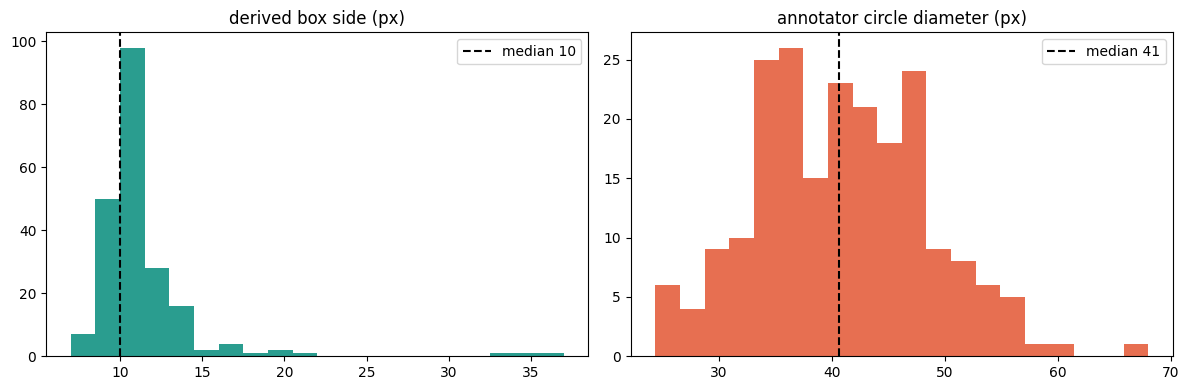

In [13]:
sides, radii, ratios, dropped = [], [], [], 0
for p in TRUTH.parasites:
    b = bx.box_at(top, p.x - ox, p.y - oy, p.radius)
    if b is None:
        dropped += 1
        continue
    sides.append(max(b.w, b.h))
    if p.radius:
        radii.append(p.radius)
        ratios.append(max(b.w, b.h) / (2 * p.radius))

s, r, q = np.array(sides), np.array(radii), np.array(ratios)
print(f'parasites {len(TRUTH.parasites)} | boxed {len(s)} | dropped {dropped} '
      f'({100*dropped/max(len(TRUTH.parasites),1):.1f}%, no stain peak)')
print(f'derived box side px   : p10 {np.percentile(s,10):.0f}  median {np.median(s):.0f}  p90 {np.percentile(s,90):.0f}')
print(f'annotator radius px   : median {np.median(r):.0f}  -> circle diameter {2*np.median(r):.0f}')
print(f'box / circle diameter : median {np.median(q):.2f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(s, bins=20, color='#2a9d8f'); ax[0].set_title('derived box side (px)')
ax[0].axvline(np.median(s), color='k', ls='--', label=f'median {np.median(s):.0f}'); ax[0].legend()
ax[1].hist(2*r, bins=20, color='#e76f51'); ax[1].set_title("annotator circle diameter (px)")
ax[1].axvline(2*np.median(r), color='k', ls='--', label=f'median {2*np.median(r):.0f}'); ax[1].legend()
plt.tight_layout(); plt.show()

### Dataset annotation vs generated annotation

The two side by side, which is the clearest statement of what this conversion
does. Left is exactly what the `.txt` file says: a `Circle` per parasite, a
`Point` per white cell. Right is what the pipeline derives from the pixels.

Top row is the whole field; bottom row is the same region at native
resolution, which is the only scale where a 10 px box is visible at all.

parasites   dataset  214  ->  generated  212
white cells dataset   28  ->  generated   28


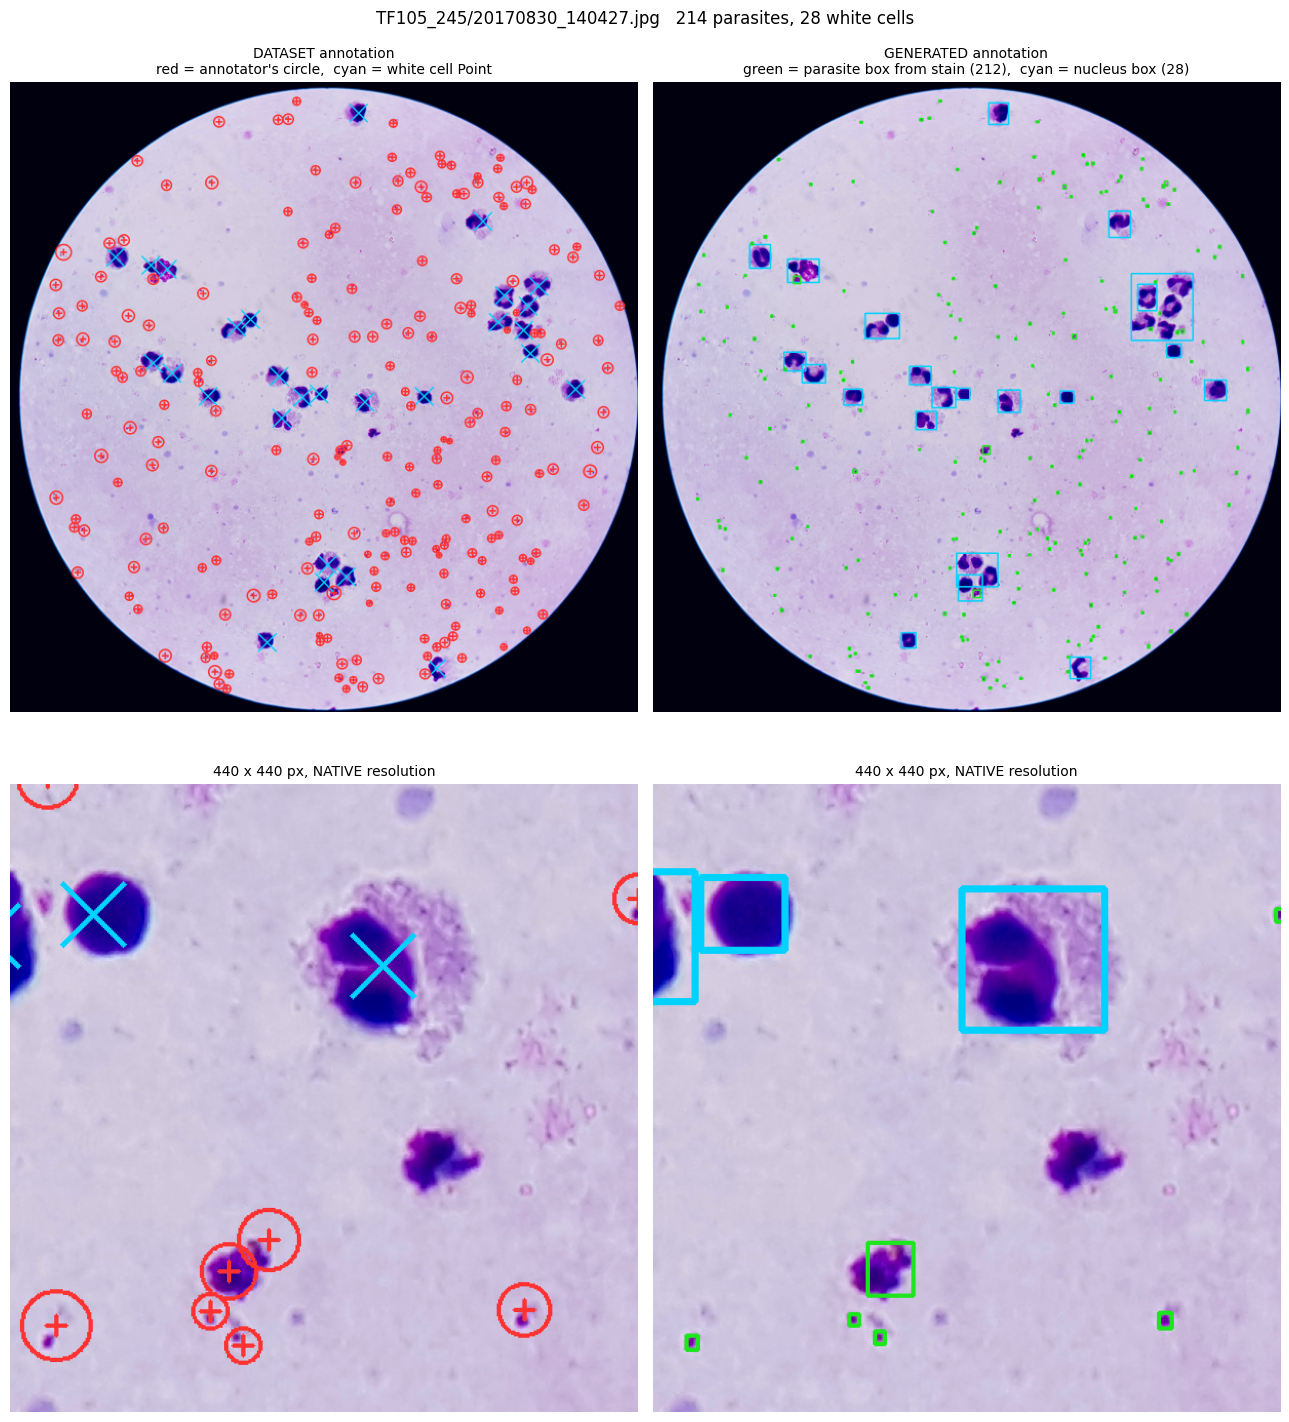

In [14]:
def draw_dataset(vis, truth, ox, oy, lw=2, cross=10):
    for a in truth.white_cells:
        cv.drawMarker(vis, (int(a.x-ox), int(a.y-oy)), (0,210,255),
                      cv.MARKER_TILTED_CROSS, cross*3, lw+1)
    for p in truth.parasites:
        c = (int(p.x-ox), int(p.y-oy))
        if p.radius:
            cv.circle(vis, c, int(p.radius), (255,50,50), lw)
        cv.drawMarker(vis, c, (255,50,50), cv.MARKER_CROSS, cross, lw)
    return vis

from autoscope import segmentation as seg

def nucleus_labels(image_bgr, mask):
    """Watershed-split nuclei at full resolution, as the pipeline builds them."""
    sm_img = cv.resize(image_bgr, None, fx=seg.SCALE, fy=seg.SCALE,
                       interpolation=cv.INTER_AREA)
    sm_msk = cv.resize(mask, (sm_img.shape[1], sm_img.shape[0]),
                       interpolation=cv.INTER_NEAREST)
    nuc = seg._nucleus_mask(sm_img, sm_msk,
                           max(int(seg.CLOSE_KERNEL_FULL*seg.SCALE) | 1, 3))
    lab = seg._split_touching(nuc)
    return cv.resize(lab.astype(np.int32), (mask.shape[1], mask.shape[0]),
                     interpolation=cv.INTER_NEAREST)

LABELS = nucleus_labels(prep, mask)

def draw_generated(vis, truth, top, labels, ox, oy, lw=2):
    """One box per annotation, both classes. Never an invented one."""
    pc = [(p.x-ox, p.y-oy) for p in truth.parasites]
    pr = [p.radius for p in truth.parasites]
    pboxes, _, _ = bx.boxes_for(top, pc, pr, fallback=False)
    wc = [(a.x-ox, a.y-oy) for a in truth.white_cells]
    wboxes, _, _ = bx.nucleus_boxes_for(labels, wc, fallback=False)
    for b in wboxes:
        cv.rectangle(vis, (b.x, b.y), (b.x+b.w, b.y+b.h), (0,210,255), lw+1)
    for b in pboxes:
        cv.rectangle(vis, (b.x, b.y), (b.x+b.w, b.y+b.h), (30,230,30), lw)
    return vis, len(pboxes), len(wboxes)

base = cv.cvtColor(prep, cv.COLOR_BGR2RGB)
full_ds = draw_dataset(base.copy(), TRUTH, ox, oy, lw=5, cross=26)
full_gen, n_box, n_nuc = draw_generated(base.copy(), TRUTH, top, LABELS, ox, oy, lw=5)
sl = (slice(y0, y0+2*R), slice(x0, x0+2*R))
crop_ds = draw_dataset(base.copy(), TRUTH, ox, oy, lw=2, cross=14)[sl]
crop_gen = draw_generated(base.copy(), TRUTH, top, LABELS, ox, oy, lw=2)[0][sl]

print(f'parasites   dataset {len(TRUTH.parasites):4d}  ->  generated {n_box:4d}')
print(f'white cells dataset {len(TRUTH.white_cells):4d}  ->  generated {n_nuc:4d}')
tiny = lambda im: cv.resize(im, None, fx=0.22, fy=0.22, interpolation=cv.INTER_AREA)

fig, axx = plt.subplots(2, 2, figsize=(13, 15))
axx[0,0].imshow(tiny(full_ds))
axx[0,0].set_title("DATASET annotation\nred = annotator's circle,  cyan = white cell Point", fontsize=10)
axx[0,1].imshow(tiny(full_gen))
axx[0,1].set_title(f'GENERATED annotation\ngreen = parasite box from stain ({n_box}),  '
                   f'cyan = nucleus box ({n_nuc})', fontsize=10)
axx[1,0].imshow(crop_ds); axx[1,0].set_title(f'{2*R} x {2*R} px, NATIVE resolution', fontsize=10)
axx[1,1].imshow(crop_gen); axx[1,1].set_title(f'{2*R} x {2*R} px, NATIVE resolution', fontsize=10)
for a in axx.ravel(): a.axis('off')
plt.suptitle(f'{IMG_PATH.parent.name}/{IMG_PATH.name}   '
             f'{len(TRUTH.parasites)} parasites, {len(TRUTH.white_cells)} white cells', fontsize=12)
plt.tight_layout(); plt.show()

### How much error the annotation itself carries

`eval/annotation_gap.py` refines every annotation against the pixels and
reports the distance. Run it here, or read the committed result. The headline:
the offset is **jitter, not bias** -- the mean displacement vector is near
zero, so there is nothing to correct -- while the stated **size** is wrong by a
factor of about 4 in radius, which is what the box derivation fixes.

Full write-up in `docs/annotation-quality.md`.

In [15]:
GAP = ROOT/'eval'/'results'/'annotation_gap.json'
if not GAP.exists():
    subprocess.run([sys.executable,'eval/annotation_gap.py','--patients','12'], cwd=str(ROOT))

g = json.loads(GAP.read_text())
p_, w_ = g['parasites'], g['white_cells']
print(f"PARASITES  {p_['refined']} of {p_['annotations']} refined")
print(f"  click to stain peak   median {p_['offset_to_stain_peak_px']['median']:.1f} px")
print(f"  mean offset vector    {p_['mean_vector_length_px']:.2f} px   "
      f"(systematic/random {p_['systematic_fraction']:.3f}  -> jitter, not bias)")
print(f"  annotated radius      {p_['annotated_radius_px']['median']:.1f} px")
print(f"  contour radius        {p_['contour_equivalent_radius_px']['median']:.1f} px")
print(f"  ratio                 {p_['radius_ratio_contour_over_annotated']['median']:.2f}"
      f"   -> the circle is ~{1/p_['radius_ratio_contour_over_annotated']['median']:.1f}x the parasite")
print(f"\nWHITE CELLS  click within the nucleus "
      f"{w_['click_within_nucleus_radius_fraction']*100:.1f}%")
print(f"  click to centroid     median {w_['offset_to_nucleus_centroid_px']['median']:.1f} px")
print(f"  nucleus radius        {w_['nucleus_equivalent_radius_px']['median']:.0f} px")

PARASITES  2209 of 2215 refined
  click to stain peak   median 7.0 px
  mean offset vector    0.33 px   (systematic/random 0.047  -> jitter, not bias)
  annotated radius      20.8 px
  contour radius        4.7 px
  ratio                 0.23   -> the circle is ~4.4x the parasite

WHITE CELLS  click within the nucleus 91.2%
  click to centroid     median 13.5 px
  nucleus radius        42 px


### Colab only: cache the export on Drive

Colab wipes its disk when the session ends, and the export takes one to two
hours. Cached on Drive, the next session starts at training instead of
repeating it. Skipped everywhere else.

The raw dataset is still downloaded each session, because the held-out scoring
reads whole fields rather than tiles.

In [16]:
CACHE_TO_DRIVE = IN_COLAB
TAR = None

if CACHE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CACHE = Path('/content/drive/MyDrive/autoscope-cache')
    CACHE.mkdir(parents=True, exist_ok=True)
    TAR = CACHE/'detect_tiles.tar'
    DEST = ROOT/'data'/'derived'
    if TAR.exists() and not (DEST/'detect'/'manifest.json').exists():
        print(f'restoring the exported tiles from {TAR} ...')
        DEST.mkdir(parents=True, exist_ok=True)
        subprocess.run(['tar','-xf',str(TAR),'-C',str(DEST)], check=True)
        done = (DEST/'detect'/'manifest.json').exists()
        print('restored' if done else 'restore produced no manifest; will re-export')
    elif TAR.exists():
        print('tiles already on disk; Drive copy left alone')
    else:
        print('no cached tiles on Drive yet; the export below will make some')
else:
    CACHE = ROOT/'data'/'derived'      # unused off Colab, but keeps names defined
    print('not on Colab: no Drive caching')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
tiles already on disk; Drive copy left alone


## 5. Export the tiled dataset -- **the decision gate**

Fit patients only. Held-out patients are never read here.

**Read the drop rate before training anything.** It is the share of annotated
parasites for which no stain peak was found. Measured on 953 parasites it is
about 1%, which is fine; above ~35% the box route is fighting the data and a
point-native (heatmap) detector is the better bet.

`SMOKE = False` is the default, because a smoke export is a trap: it succeeds,
it looks like a dataset, and a model trained on its 55 tiles reports
mAP50 0.966 while having memorised four patients. That happened. Set
`SMOKE = True` only to rehearse the path, and never train on the result.

The real export writes to `data/derived/detect`; the smoke one to
`data/derived/detect_smoke`, so they cannot overwrite each other -- and the
training cells read whichever `OUT` points at, so check the tile counts the
manifest prints before training.

In [17]:
SMOKE = False                # True only to rehearse the path on 4 patients
IMAGES_PER_PATIENT = 10      # ~12 annotated images exist per patient
FORCE_REEXPORT = False       # True to discard a finished export and redo it

OUT = ROOT/'data'/'derived'/('detect_smoke' if SMOKE else 'detect')

# The export DELETES the output directory before writing, so re-running this
# cell on a finished export throws away hours of work. A complete export is
# left alone unless you ask for it to be replaced.
if (OUT/'manifest.json').exists() and not FORCE_REEXPORT:
    print(f'a COMPLETE export already exists at {OUT} -- skipping.')
    print('set FORCE_REEXPORT = True to discard and rebuild it.')
elif OUT.exists() and not (OUT/'manifest.json').exists():
    print(f'{OUT} holds an INTERRUPTED export (no manifest.json).')
    print('re-running: the export clears it first.')
    FORCE_REEXPORT = True

if FORCE_REEXPORT or not (OUT/'manifest.json').exists():
    cmd = [sys.executable, '-u', 'eval/export_detection.py',
           '--images-per-patient', str(2 if SMOKE else IMAGES_PER_PATIENT),
           '--out', str(OUT)]
    if SMOKE:
        cmd += ['--max-patients', '4']
    print(' '.join(cmd), '\n')
    print('this takes 1-2 hours for the full set. From a terminal instead:')
    print(f'  nohup python eval/export_detection.py --images-per-patient '
          f'{IMAGES_PER_PATIENT} > export.log 2>&1 &\n')
    r = subprocess.run(cmd, cwd=str(ROOT), capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode:
        print('STDERR:\n', r.stderr[-3000:])

a COMPLETE export already exists at /content/autoscope-opencv/data/derived/detect -- skipping.
set FORCE_REEXPORT = True to discard and rebuild it.


In [18]:
import json
m = json.loads((OUT/'manifest.json').read_text())
print(f"split source        {m['split_source']}")
print(f"train/val patients  {m['train_patients']} / {m['val_patients']}")
print(f"held out, untouched {m['holdout_patients_untouched']}")
print(f"tiles               train {m['counts'].get('tiles_train',0)}, val {m['counts'].get('tiles_val',0)}")
c = m.get('counts', {})
# .get() throughout: an export made by an older commit is missing some of
# these, and a KeyError here would be a worse answer than "(absent)".
print(f"\nannotated parasites {m.get('annotated_parasites')}")
print(f"boxes derived       {m.get('boxes_derived')}   (all contoured from the stain)")
print(f"boxes INVENTED      {m.get('boxes_invented', '(absent)')}   <- must stay 0")
print(f"unboxable           {m.get('annotations_unboxable')}, and the "
      f"{m.get('tiles_dropped_unboxable')} tiles holding them were dropped")
print(f"DROP RATE           {m.get('box_drop_rate', 0)*100:.2f}%    <- read this")
print(f"boxes covered       {m.get('boxes_covered', '(absent)')} "
      f"({m.get('box_tile_loss_rate', 0)*100:.1f}% never reached a tile), written as "
      f"{m.get('box_instances_written', '?')} label lines")
print(f"reserved, not used  {c.get('images_reserved_for_inference', 0)} images")
print(f"box side px         p10 {m.get('box_side_p10_px')}, "
      f"median {m.get('box_side_median_px')}, p90 {m.get('box_side_p90_px')}")

print(f"\nTILES               train {c.get('tiles_train')}, val {c.get('tiles_val')}")
print(f"BOXES               train {c.get('boxes_train')}, val {c.get('boxes_val')}")

print(f"\nprovenance")
print(f"  min_fov           {m.get('min_fov', '(absent)')}")
print(f"  git revision      {m.get('git_revision', '(absent)')}")
print(f"  seed              {m.get('seed')}")
if m.get('min_fov') is None:
    rejected = c.get('tiles_outside_fov', 0) / max(c.get('images', 1), 1)
    print(f"\n  min_fov is not recorded, but {rejected:.2f} tiles per image were")
    print(f"  rejected for coverage. ~1.8 means 0.2 (correct); ~19 means 0.9")
    print(f"  (discards two thirds of the field).")

split source        eval/results/wbc_sweep.json:fit_patients
train/val patients  80 / 20
held out, untouched 50
tiles               train 13510, val 2764

annotated parasites 41043
boxes derived       40556   (all contoured from the stain)
boxes INVENTED      0   <- must stay 0
unboxable           487, and the 647 tiles holding them were dropped
DROP RATE           1.19%    <- read this
boxes covered       38691 (4.6% never reached a tile), written as 60295 label lines
reserved, not used  26 images
box side px         p10 8.0, median 11.0, p90 20.0

TILES               train 13510, val 2764
BOXES               train 50645, val 9650

provenance
  min_fov           0.2
  git revision      51547aa
  seed              0


In [19]:
# Save the finished export to Drive, so a later session skips the hour.
if CACHE_TO_DRIVE and TAR is not None and (OUT/'manifest.json').exists():
    if TAR.exists():
        print(f'{TAR} already exists; delete it to replace the cached copy')
    else:
        print(f'caching {OUT.name} to {TAR} ...')
        subprocess.run(['tar','-cf',str(TAR),'-C',str(OUT.parent),OUT.name], check=True)
        print(f'cached: {TAR.stat().st_size/1e9:.1f} GB')

/content/drive/MyDrive/autoscope-cache/detect_tiles.tar already exists; delete it to replace the cached copy


### The exported tiles, as the detector will see them

This is the last chance to catch a labelling bug before a GPU spends hours
learning it.

11908 of 13510 train tiles carry a box


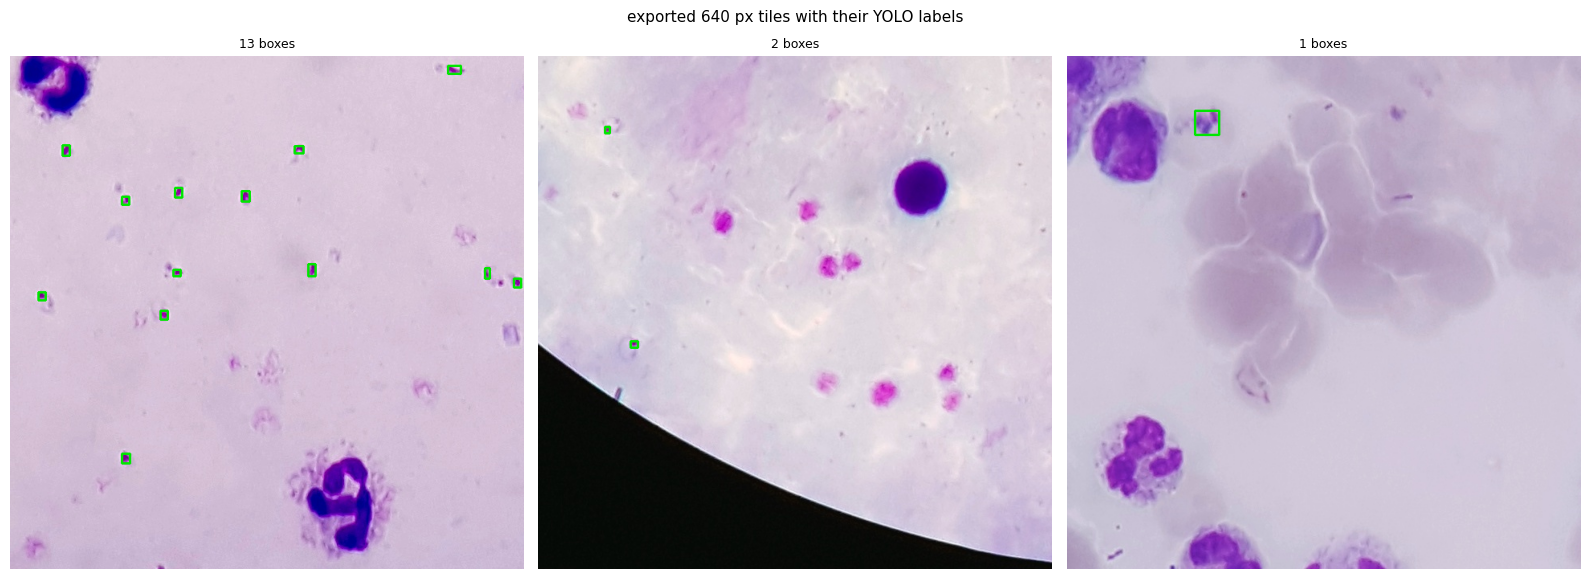

In [20]:
import random

img_dir, lab_dir = OUT/'images'/'train', OUT/'labels'/'train'
withboxes = [p for p in sorted(img_dir.glob('*.jpg'))
             if (lab_dir/(p.stem+'.txt')).read_text().strip()]
print(f'{len(withboxes)} of {len(list(img_dir.glob("*.jpg")))} train tiles carry a box')

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, p in zip(axes, random.Random(0).sample(withboxes, min(3, len(withboxes)))):
    im = cv.cvtColor(cv.imread(str(p)), cv.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    n = 0
    for line in (lab_dir/(p.stem+'.txt')).read_text().splitlines():
        if not line.strip(): continue
        _, cx_, cy_, bw, bh = (float(v) for v in line.split())
        X0, Y0 = int((cx_-bw/2)*w), int((cy_-bh/2)*h)
        cv.rectangle(im, (X0, Y0), (X0+int(bw*w), Y0+int(bh*h)), (0, 230, 0), 2)
        n += 1
    ax.imshow(im); ax.set_title(f'{n} boxes', fontsize=9); ax.axis('off')
plt.suptitle('exported 640 px tiles with their YOLO labels', fontsize=11)
plt.tight_layout(); plt.show()

### Numeric check: are the labels actually on parasites?

An eyeball can miss a systematic few-pixel offset. The top-hat stain under the
box centres should be far above background.

In [21]:
on, off = [], []
rng = np.random.default_rng(0)
for p in withboxes[:40]:
    im = cv.imread(str(p)); h, w = im.shape[:2]
    t_, _, _ = par.tophat(im)
    for line in (lab_dir/(p.stem+'.txt')).read_text().splitlines():
        if not line.strip(): continue
        _, cx_, cy_, _, _ = (float(v) for v in line.split())
        on.append(t_[int(cy_*h), int(cx_*w)])
    off.extend(t_[rng.integers(0,h,40), rng.integers(0,w,40)])

print(f'{len(on)} box centres checked')
print(f'top-hat stain at box centres : median {np.median(on):.1f}')
print(f'top-hat at random pixels     : median {np.median(off):.1f}')
print(f'-> boxes sit on {np.median(on)/max(np.median(off),0.01):.0f}x the stain of background')

52 box centres checked
top-hat stain at box centres : median 73.3
top-hat at random pixels     : median 1.0
-> boxes sit on 74x the stain of background


## 6. Train YOLO26

Check the manifest above says **13 510 train tiles**, not 55. A model trained
on the smoke export reports excellent numbers and has memorised four patients.

Augmentation is turned down on purpose: mosaic would halve the apparent size of
a 10 px parasite.

**Timing.** Measured on a T4: 403 s for the first epoch, so about 6.7 minutes
each. `--cache disk` writes a decoded `.npy` beside every tile on the first
pass, which removes the JPEG decode from every later epoch -- worth it when the
VM has two cores and the GPU is waiting on them. Worker count now defaults to
one per core rather than 8, for the same reason.

**`RESUME` restores the old settings too.** Ultralytics resumes from the
checkpoint, which carries the arguments the run started with -- so a resumed
run keeps its original `--epochs` and ignores `--cache`. Resume to continue a
long run a session killed; start fresh whenever the settings have changed, and
accept losing the epochs already done.

One way to tell what a checkpoint on Drive actually trained on: an epoch of
about 400 s is the real 13 510-tile dataset. An epoch of a few seconds is the
smoke set, and nothing built on it is worth continuing.

**The run goes to local disk; Drive gets a copy after every epoch.**

Writing the run *directly* to Drive does not work, and fails silently:
ultralytics rewrites the same files every epoch, Drive is a FUSE mount, and the
result is a finished run with an empty weights directory and no error anywhere.
That is what cost the last attempt.

So the run stays on the VM, which is fast and reliable, and `--mirror` copies
`last.pt` and `best.pt` to Drive after each epoch. A session ending costs the
epoch in progress.

Both destinations are probed with a real 1 MB write before training starts, so
an unwritable path fails in seconds rather than hours. If the first epoch
produces no checkpoint, the run stops immediately rather than continuing to
produce nothing.

On a fresh session the cell copies any previous run back from Drive first. Set
`RESUME = True` to continue it, with the optimiser state and epoch counter
intact.

In [23]:
# Measured on a T4 with this dataset: 403 s for epoch 1, so about 6.7 min an
# epoch. 150 epochs is ~17 hours and no Colab session lasts that long. 40 fits
# inside one session at roughly 4.5 hours, and with patience=25 a run that has
# stopped improving will end before then anyway.
#
# If you want more than fits in a session: leave it running, let the session
# die, then come back, set RESUME = True and run this cell again. Checkpoints
# are on Drive, so it picks up where it stopped.
EPOCHS_YOLO = 10
RESUME = True        # True ONLY to continue a run you watched die

# Train to LOCAL disk and mirror to Drive after each epoch. Writing the run
# directly to Drive does not work: ultralytics rewrites the same files every
# epoch, Drive is a FUSE mount, and the failure is silent -- the run completes
# and the weights directory is empty. Local is fast and reliable; the mirror is
# what survives the session ending.
MODELS = ROOT/'models'/'yolo26'
MIRROR = (CACHE/'models'/'yolo26') if CACHE_TO_DRIVE else None
RUN = MODELS/'yolo26'

# A new session starts with an empty VM. If Drive holds a previous run, copy it
# back so --resume has something to resume from.
if MIRROR and (MIRROR/'yolo26'/'weights'/'last.pt').exists() and not (RUN/'weights'/'last.pt').exists():
    print('restoring a previous run from Drive ...')
    (RUN/'weights').mkdir(parents=True, exist_ok=True)
    for f in (MIRROR/'yolo26'/'weights').glob('*.pt'):
        shutil.copy2(f, RUN/'weights'/f.name)
    for extra in ('results.csv','args.yaml','dataset.json'):
        if (MIRROR/'yolo26'/extra).exists():
            shutil.copy2(MIRROR/'yolo26'/extra, RUN/extra)
    print('restored; set RESUME = True to continue it')

print('run dir ->', RUN)
print('mirror  ->', MIRROR or '(none: not on Colab)')

cmd = [sys.executable,'-u','train/yolo26.py','--data',str(OUT),
       '--epochs',str(EPOCHS_YOLO),'--batch','16','--no-clearml',
       '--out',str(MODELS),'--cache','disk']
if MIRROR:
    cmd += ['--mirror', str(MIRROR)]
if RESUME:
    cmd.append('--resume')
print(' '.join(cmd),'\n')
r = subprocess.run(cmd, cwd=str(ROOT))
print('exit', r.returncode)

YOLO_W = RUN/'weights'/'best.pt'
print('\nweights:', YOLO_W, '|', 'present' if YOLO_W.exists() else 'MISSING')
if (RUN/'dataset.json').exists():
    print('trained on:', json.loads((RUN/'dataset.json').read_text()))

run dir -> /content/autoscope-opencv/models/yolo26/yolo26
mirror  -> /content/drive/MyDrive/autoscope-cache/models/yolo26
/usr/bin/python3 -u train/yolo26.py --data /content/autoscope-opencv/data/derived/detect --epochs 10 --batch 16 --no-clearml --out /content/autoscope-opencv/models/yolo26 --cache disk --mirror /content/drive/MyDrive/autoscope-cache/models/yolo26 --resume 



KeyboardInterrupt: 

## 7. Choose the threshold -- on VAL, never on holdout

`detector_eval.py` will refuse this sweep against the held-out split.

In [22]:
r = subprocess.run([sys.executable,'eval/detector_eval.py','--backend','yolo',
                    '--weights',str(YOLO_W),'--split','val','--sweep',
                    '--per-patient','3'], cwd=str(ROOT))
print('exit', r.returncode)

NameError: name 'YOLO_W' is not defined

## 8. Faster R-CNN, same tiles

Slower. Checkpoints are written every epoch, so an interruption costs one epoch.

In [ ]:
EPOCHS_FRCNN = 20
RESUME_FRCNN = False

FRCNN_DIR = ROOT/'models'/'frcnn'
FRCNN_MIRROR = (CACHE/'models'/'frcnn') if CACHE_TO_DRIVE else None
FRCNN_DIR.mkdir(parents=True, exist_ok=True)

# Bring a previous run back from Drive so --resume has checkpoints to find.
if FRCNN_MIRROR and FRCNN_MIRROR.exists():
    restored = 0
    for f in sorted(FRCNN_MIRROR.glob('epoch*.pt')):
        if not (FRCNN_DIR/f.name).exists():
            shutil.copy2(f, FRCNN_DIR/f.name); restored += 1
    if restored:
        print(f'restored {restored} checkpoints from Drive; '
              'set RESUME_FRCNN = True to continue')

print('run dir ->', FRCNN_DIR)
print('mirror  ->', FRCNN_MIRROR or '(none: not on Colab)')

cmd = [sys.executable,'-u','train/frcnn.py','--data',str(OUT),
       '--epochs',str(EPOCHS_FRCNN),'--batch','4','--workers','2',
       '--no-clearml','--out',str(FRCNN_DIR)]
if FRCNN_MIRROR:
    cmd += ['--mirror', str(FRCNN_MIRROR)]
if RESUME_FRCNN:
    cmd.append('--resume')
print(' '.join(cmd),'\n')
r = subprocess.run(cmd, cwd=str(ROOT))
print('exit', r.returncode)

ckpts = sorted(FRCNN_DIR.glob('epoch*.pt'))
FRCNN_W = ckpts[-1] if ckpts else None
print('checkpoints:', len(ckpts), '| using', FRCNN_W)

In [ ]:
r = subprocess.run([sys.executable,'eval/detector_eval.py','--backend','frcnn',
                    '--weights',str(FRCNN_W),'--split','val','--sweep',
                    '--per-patient','3'], cwd=str(ROOT))
print('exit', r.returncode)

## 9. The held-out 50 -- run **once**

Everything above happened on fit patients. Set each threshold from its val
sweep **before** running these. Re-running with different thresholds until one
looks good is fitting on the held-out set, and it would invalidate the
generalisation claim the project rests on.

In [ ]:
THRESHOLD_YOLO = 0.25    # <- from the YOLO val sweep

r = subprocess.run([sys.executable,'eval/detector_eval.py','--backend','yolo',
                    '--weights',str(YOLO_W),'--split','holdout',
                    '--threshold',str(THRESHOLD_YOLO),'--per-patient','3',
                    '--tag','yolo26_holdout'], cwd=str(ROOT))
print('exit', r.returncode)

In [ ]:
THRESHOLD_FRCNN = 0.25   # <- from the Faster R-CNN val sweep

r = subprocess.run([sys.executable,'eval/detector_eval.py','--backend','frcnn',
                    '--weights',str(FRCNN_W),'--split','holdout',
                    '--threshold',str(THRESHOLD_FRCNN),'--per-patient','3',
                    '--tag','frcnn_holdout'], cwd=str(ROOT))
print('exit', r.returncode)

## 10. The comparison

In [ ]:
RES = ROOT/'eval'/'results'
print(f"{'model':<12}{'thr':>6}{'prec':>9}{'recall':>9}{'F1':>9}{'bias%':>10}")
for f in sorted(RES.glob('detector_eval_*holdout*.json')):
    d = json.loads(f.read_text())
    for thr, v in d['by_threshold'].items():
        print(f"{d['backend']:<12}{thr:>6}{v['precision']:>9.3f}"
              f"{v['recall']:>9.3f}{v['f1']:>9.3f}{v['count_bias_pct']:>+10.1f}")
print(f"{'patch CNN':<12}{'0.75':>6}{0.790:>9.3f}{0.739:>9.3f}{0.763:>9.3f}{-6.4:>+10.1f}   <- to beat")
print('\nA better F1 with a worse count bias is not a better detector:')
print('the count is the denominator of every density.')